# ДЗ №1. Классификация спутниковых снимков EuroSAT

Задача — определить тип местности по спутниковому снимку: реку, шоссе, промзону, жилую застройку и ещё шесть классов. Данные — **EuroSAT RGB**: 27 000 цветных снимков Sentinel-2, по 10 классов. [Описание датасета](https://zenodo.org/records/7711810) и [статья Helber et al., 2019](https://doi.org/10.1109/JSTARS.2019.2918242).

Сравниваю две архитектуры: **ResNet-18** и **MobileNetV3-Small**. Обе загружены с весами ImageNet. В работе применяю три техники:

1. **Итеративная аугментация**: weak → medium → strong.
2. **Итеративная разморозка** с дифференциальным learning rate: голова → верхний блок → вся сеть.
3. **Псевдолейблинг**: два раунда самообучения на неразмеченном пуле с контролем качества.

Разметки мало: 2 000 снимков (7.4% датасета). Ещё 19 600 снимков используются как пул без меток, по 2 700 — валидация и тест. Все модели обучаются на одном и том же разбиении.

Ноутбук запускается сверху вниз; датасет скачивается автоматически. Точные числа могут немного отличаться на другом устройстве (CUDA/CPU), но порядок методов и выводы устойчивы. Веса моделей не сохраняются на диск.

## 1. Импорты и настройки

In [1]:
from __future__ import annotations

import random
from collections.abc import Callable
from dataclasses import dataclass
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from torchvision.datasets import EuroSAT

### Настройки

In [2]:
SEED = 42
DATA_DIR = Path("data")
IMAGE_SIZE = 96
BATCH_SIZE = 64
LABELED_COUNT = 2_000
HOLDOUT_FRACTION = 0.10
PRETRAINED = True
PSEUDO_WEIGHT = 0.4
MAX_PSEUDO_PER_CLASS = 250
PSEUDO_THRESHOLDS = (0.90, 0.85)
ROUND_EPOCHS = 3
N_BOOTSTRAP = 3_000
BOOTSTRAP_SEED = SEED + 1
NUM_WORKERS = 0

DEVICE: torch.device
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

plt.rcParams.update(
    {
        "figure.dpi": 105,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.labelcolor": "#314155",
        "text.color": "#24364b",
    }
)

Architecture = Literal["ResNet-18", "MobileNetV3-Small"]
Scope = Literal["head", "upper", "all"]
Augmentation = Literal["weak", "medium", "strong"]

ARCHITECTURES: tuple[Architecture, ...] = (
    "ResNet-18",
    "MobileNetV3-Small",
)
COMMON_EXPERIMENT = "Общее обучение"
BRANCH_EXPERIMENTS = ("Контроль", "Псевдометки")
BRANCH_COLORS = {
    COMMON_EXPERIMENT: "#4b5563",
    "Контроль": "#315f93",
    "Псевдометки": "#c57640",
}
criterion: nn.CrossEntropyLoss = nn.CrossEntropyLoss()

print(f"Устройство: {DEVICE} | PyTorch: {torch.__version__}")

Устройство: mps | PyTorch: 2.8.0


### Данные и разбиение

Разбиение стратифицированное: пропорции классов сохраняются. Валидация используется для выбора learning rate и лучшего чекпойнта, тест — только для итогового сравнения. Пул без меток не пересекается с валидацией и тестом.

In [3]:
eurosat: EuroSAT = EuroSAT(DATA_DIR, download=True)
paths: np.ndarray = np.array([path for path, _ in eurosat.samples])
targets: np.ndarray = np.asarray(eurosat.targets)
class_names: list[str] = list(eurosat.classes)
class_ids: list[int] = list(range(len(class_names)))

train_val_idx, test_idx = train_test_split(
    np.arange(len(eurosat)),
    test_size=HOLDOUT_FRACTION,
    stratify=targets,
    random_state=SEED,
)
train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=HOLDOUT_FRACTION / (1.0 - HOLDOUT_FRACTION),
    stratify=targets[train_val_idx],
    random_state=SEED,
)
labeled_idx, unlabeled_idx = train_test_split(
    train_idx,
    train_size=LABELED_COUNT,
    stratify=targets[train_idx],
    random_state=SEED,
)

all_indices: np.ndarray = np.concatenate(
    [labeled_idx, unlabeled_idx, val_idx, test_idx]
)
assert len(all_indices) == len(eurosat)
assert len(np.unique(all_indices)) == len(eurosat)
assert set(labeled_idx).isdisjoint(unlabeled_idx)
assert set(labeled_idx).isdisjoint(val_idx)
assert set(labeled_idx).isdisjoint(test_idx)
assert set(unlabeled_idx).isdisjoint(val_idx)
assert set(unlabeled_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)
assert len(labeled_idx) == LABELED_COUNT
assert np.bincount(targets[labeled_idx], minlength=len(class_ids)).min() > 0

split_sizes: pd.Series = pd.Series(
    {
        "Размеченное обучение": len(labeled_idx),
        "Пул без меток": len(unlabeled_idx),
        "Валидация": len(val_idx),
        "Тест": len(test_idx),
    },
    name="Снимки",
)
display(split_sizes.to_frame())

split_counts: pd.DataFrame = pd.DataFrame(
    {
        "Размечено": np.bincount(targets[labeled_idx], minlength=len(class_names)),
        "Пул": np.bincount(targets[unlabeled_idx], minlength=len(class_names)),
        "Валидация": np.bincount(targets[val_idx], minlength=len(class_names)),
        "Тест": np.bincount(targets[test_idx], minlength=len(class_names)),
    },
    index=class_names,
)
split_counts.index.name = "Класс"
display(split_counts)

,Снимки
Размеченное обучение,2000
Пул без меток,19600
Валидация,2700
Тест,2700


,Размечено,Пул,Валидация,Тест
Класс,,,,
AnnualCrop,222,2178,300,300
Forest,223,2177,300,300
HerbaceousVegetation,222,2178,300,300
Highway,185,1815,250,250
Industrial,185,1815,250,250
Pasture,148,1452,200,200
PermanentCrop,185,1815,250,250
Residential,222,2178,300,300
River,185,1815,250,250


### Примеры снимков из размеченной части

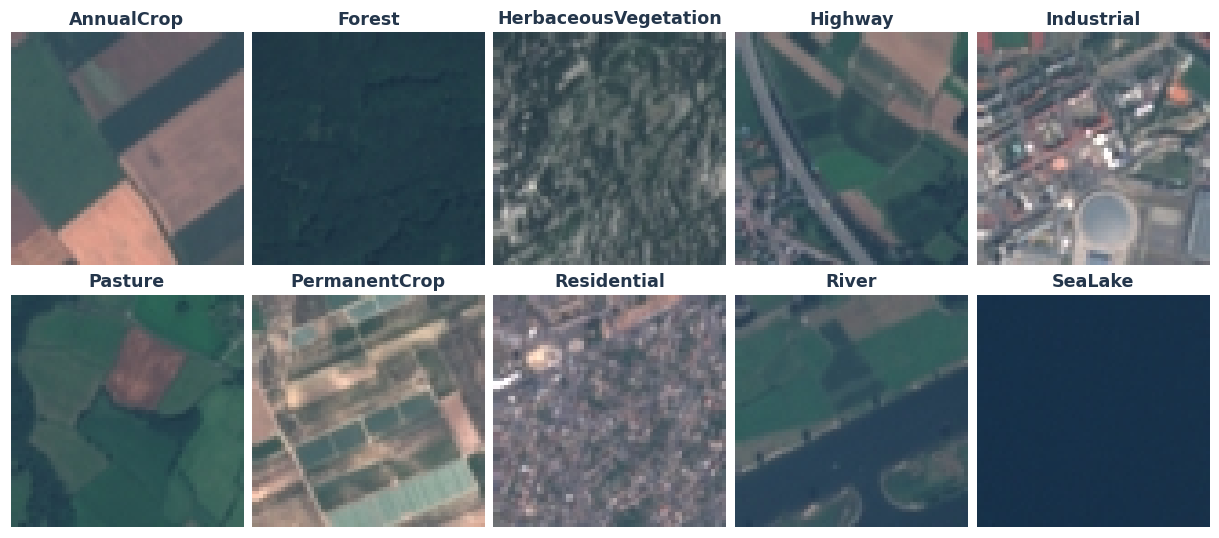

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(11.5, 5.0), layout="constrained")
for class_id, ax in enumerate(axes.flat):
    sample_index = labeled_idx[targets[labeled_idx] == class_id][0]
    with Image.open(paths[sample_index]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(class_names[class_id])
    ax.axis("off")
for ax in axes.flat[len(class_names) :]:
    ax.axis("off")
plt.show()

## 2. Аугментация и датасет

Аугментация усложняется по мере разморозки:

- **weak** — отражения по горизонтали и вертикали. Для снимка сверху это допустимо: река или поле остаются тем же классом.
- **medium** — случайное кадрирование и небольшие изменения яркости/контраста.
- **strong** — более агрессивное кадрирование, насыщенность и случайное стирание небольшой области.

Для валидации, теста и получения псевдометок используется детерминированное преобразование без случайных операций.

In [5]:
NORMALIZE = transforms.Normalize(
    mean=(0.485, 0.456, 0.406),
    std=(0.229, 0.224, 0.225),
)
RESIZE = transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))
TO_NORMALIZED = [transforms.ToTensor(), NORMALIZE]
EVAL_TRANSFORM = transforms.Compose([RESIZE, *TO_NORMALIZED])
FLIPS = [
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
]
AUGMENTATIONS: dict[Augmentation, Callable[[Image.Image], torch.Tensor]] = {
    "weak": transforms.Compose([RESIZE, *FLIPS, *TO_NORMALIZED]),
    "medium": transforms.Compose(
        [
            transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.85, 1.0)),
            *FLIPS,
            transforms.ColorJitter(brightness=0.15, contrast=0.15),
            *TO_NORMALIZED,
        ]
    ),
    "strong": transforms.Compose(
        [
            transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.75, 1.0)),
            *FLIPS,
            transforms.ColorJitter(
                brightness=0.2,
                contrast=0.2,
                saturation=0.15,
            ),
            *TO_NORMALIZED,
            transforms.RandomErasing(p=0.25, scale=(0.02, 0.10)),
        ]
    ),
}


class SatelliteImages(Dataset):
    """Return an image tensor and a label (or dataset index)."""

    def __init__(
        self,
        indices: np.ndarray,
        transform: Callable[[Image.Image], torch.Tensor],
        labels: np.ndarray | None = None,
    ) -> None:
        self.indices: np.ndarray = np.asarray(indices)
        self.paths: np.ndarray = paths[self.indices]
        self.transform: Callable[[Image.Image], torch.Tensor] = transform
        self.labels: np.ndarray | None = labels

    def __len__(self) -> int:
        return len(self.indices)

    def __getitem__(self, position: int) -> tuple[torch.Tensor, int]:
        with Image.open(self.paths[position]) as image:
            tensor = self.transform(image.convert("RGB"))
        if self.labels is None:
            # The unlabeled pool returns its original index, so pseudo
            # labels can be mapped back to the dataset.
            return tensor, int(self.indices[position])
        return tensor, int(self.labels[position])


def make_loader(
    dataset: Dataset,
    shuffle: bool = False,
    seed: int = SEED,
) -> DataLoader:
    """Build a deterministic DataLoader for the current device."""
    generator = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        generator=generator,
        pin_memory=DEVICE.type == "cuda",
    )


val_loader: DataLoader = make_loader(
    SatelliteImages(val_idx, EVAL_TRANSFORM, targets[val_idx])
)
unlabeled_loader: DataLoader = make_loader(
    SatelliteImages(unlabeled_idx, EVAL_TRANSFORM)
)

## 3. Модели, фазы и чекпойнты

Фазы обучения:

1. Обучение только классификатора, слабая аугментация.
2. Классификатор, средняя аугментация.
3. Разморозка верхнего блока (у ResNet-18 — `layer4`, у MobileNetV3 — последние три модуля `features`), дифференциальный lr.
4. Полная разморозка, сильная аугментация.

Внутри фазы `ReduceLROnPlateau` снижает lr, если `val_loss` перестаёт улучшаться. После каждой фазы сохраняется лучший по `val_loss` чекпойнт. Для итоговой модели берётся **лучший чекпойнт среди всех фаз**, а не чекпойнт последней фазы: это важно, если полная разморозка ухудшает качество.

In [6]:
@dataclass
class ModelParts:
    model: nn.Module
    head: nn.Module
    upper_block: nn.Module


@dataclass(frozen=True)
class TrainingPhase:
    name: str
    scope: Scope
    augmentation: Augmentation
    epochs: int
    head_lr: float
    backbone_lr: float


@dataclass(frozen=True)
class Checkpoint:
    name: str
    val_loss: float
    val_accuracy: float
    val_macro_f1: float
    epoch: int
    weights: dict[str, torch.Tensor]


@dataclass(frozen=True)
class PseudoSelection:
    chosen: pd.DataFrame
    candidates: int
    threshold: float


@dataclass(frozen=True)
class BranchOutcome:
    checkpoint: Checkpoint
    improved: bool
    pseudo_labels: int


PHASES: tuple[TrainingPhase, ...] = (
    TrainingPhase("1. Классификатор", "head", "weak", 2, 1e-3, 0.0),
    TrainingPhase("2. Средняя аугментация", "head", "medium", 2, 5e-4, 0.0),
    TrainingPhase("3. Верхний блок", "upper", "medium", 3, 4e-4, 8e-5),
    TrainingPhase("4. Полная разморозка", "all", "strong", 4, 2e-4, 4e-5),
)
COMMON_EPOCHS = sum(phase.epochs for phase in PHASES)


def build_model(architecture: Architecture) -> ModelParts:
    """Build a pretrained backbone and replace its classifier."""
    if architecture == "ResNet-18":
        weights = models.ResNet18_Weights.DEFAULT if PRETRAINED else None
        model = models.resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, len(class_names))
        head = model.fc
        upper_block = model.layer4
    elif architecture == "MobileNetV3-Small":
        weights = models.MobileNet_V3_Small_Weights.DEFAULT if PRETRAINED else None
        model = models.mobilenet_v3_small(weights=weights)
        model.classifier[-1] = nn.Linear(
            model.classifier[-1].in_features, len(class_names)
        )
        head = model.classifier
        upper_block = model.features[-3:]
    else:
        raise ValueError(f"Unknown architecture: {architecture}")

    model = model.to(DEVICE)
    return ModelParts(model=model, head=head, upper_block=upper_block)


def set_trainable_scope(parts: ModelParts, scope: Scope) -> None:
    """Freeze everything except the modules required by the scope."""
    parts.model.requires_grad_(scope == "all")
    parts.head.requires_grad_(True)
    if scope == "upper":
        parts.upper_block.requires_grad_(True)


def configure_optimizer(
    parts: ModelParts,
    scope: Scope,
    head_lr: float,
    backbone_lr: float,
) -> torch.optim.AdamW:
    """Create AdamW with separate learning rates for head and backbone."""
    set_trainable_scope(parts, scope)
    head_params = list(parts.head.parameters())
    head_ids = {id(parameter) for parameter in head_params}
    backbone_params = [
        parameter
        for parameter in parts.model.parameters()
        if parameter.requires_grad and id(parameter) not in head_ids
    ]
    groups = [{"params": head_params, "lr": head_lr, "name": "head"}]
    if backbone_params:
        groups.append(
            {
                "params": backbone_params,
                "lr": backbone_lr,
                "name": "backbone",
            }
        )
    return torch.optim.AdamW(groups, weight_decay=1e-4)


def save_weights(model: nn.Module) -> dict[str, torch.Tensor]:
    """Clone a state dict on CPU to avoid keeping device tensors."""
    return {
        key: value.detach().cpu().clone() for key, value in model.state_dict().items()
    }

### Сколько параметров обучается на каждой фазе

У ResNet-18 заменён только последний линейный слой: это 5 130 параметров из 11.2M, поэтому на первых фазах доля обучаемых весов около 0.05%. У MobileNetV3-Small классификатор крупнее, поэтому его доля выше.

In [7]:
parameter_rows: list[dict[str, object]] = []
for architecture in ARCHITECTURES:
    parts = build_model(architecture)
    total_parameters = sum(parameter.numel() for parameter in parts.model.parameters())
    for phase in PHASES:
        set_trainable_scope(parts, phase.scope)
        trainable = sum(
            parameter.numel()
            for parameter in parts.model.parameters()
            if parameter.requires_grad
        )
        parameter_rows.append(
            {
                "Архитектура": architecture,
                "Фаза": phase.name,
                "Обучаемые": trainable,
                "Всего": total_parameters,
                "Доля": trainable / total_parameters,
            }
        )

parameter_table: pd.DataFrame = pd.DataFrame(parameter_rows)
display(
    parameter_table.style.format(
        {
            "Обучаемые": "{:,}",
            "Всего": "{:,}",
            "Доля": "{:.2%}",
        }
    ).hide(axis="index")
)

Архитектура,Фаза,Обучаемые,Всего,Доля
ResNet-18,1. Классификатор,"5,130","11,181,642",0.05%
ResNet-18,2. Средняя аугментация,"5,130","11,181,642",0.05%
ResNet-18,3. Верхний блок,"8,398,858","11,181,642",75.11%
ResNet-18,4. Полная разморозка,"11,181,642","11,181,642",100.00%
MobileNetV3-Small,1. Классификатор,"601,098","1,528,106",39.34%
MobileNetV3-Small,2. Средняя аугментация,"601,098","1,528,106",39.34%
MobileNetV3-Small,3. Верхний блок,"1,245,738","1,528,106",81.52%
MobileNetV3-Small,4. Полная разморозка,"1,528,106","1,528,106",100.00%


## 4. Обучение

Ключевые детали:

- Замороженные BatchNorm-слои остаются в режиме `eval`, чтобы их статистики не обновлялись.
- Ветки «контроль» и «псевдометки» стартуют с одного и того же лучшего по `val_loss` чекпойнта и делают одинаковое число шагов оптимизатора. В обеих ветках `head_lr=1e-4`, `backbone_lr=2e-5`, по 3 эпохи в раунде.
- Стартовый чекпойнт участвует в выборе лучшего состояния ветки: если дообучение ухудшает `val_loss`, ветка возвращает стартовое состояние.
- Псевдометки выбираются по уверенности модели; на каждый предсказанный класс берётся не более `MAX_PSEUDO_PER_CLASS` снимков. Эталонные метки пула используются только для диагностики точности псевдометок, но никогда — в обучении.

In [8]:
def seed_everything(seed: int) -> None:
    """Seed Python, NumPy and PyTorch (including CUDA)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def train_epoch(
    model: nn.Module,
    optimizer: torch.optim.Optimizer,
    labeled_loader: DataLoader,
    pseudo_loader: DataLoader | None = None,
) -> dict[str, float]:
    """Train one epoch, optionally adding a weighted pseudo-label loss."""
    model.train()
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d) and (
            module.weight is None or not module.weight.requires_grad
        ):
            # Frozen BatchNorm layers must not update running statistics.
            module.eval()

    pseudo_iterator = iter(pseudo_loader) if pseudo_loader is not None else None
    labeled_sum = 0.0
    pseudo_sum = 0.0
    labeled_count = 0
    pseudo_count = 0

    for images, labels in labeled_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)

        if pseudo_iterator is None:
            logits = model(images)
            labeled_loss = criterion(logits, labels)
            loss = labeled_loss
        else:
            try:
                pseudo_images, pseudo_labels = next(pseudo_iterator)
            except StopIteration:
                pseudo_iterator = iter(pseudo_loader)
                pseudo_images, pseudo_labels = next(pseudo_iterator)
            pseudo_images = pseudo_images.to(DEVICE)
            pseudo_labels = pseudo_labels.to(DEVICE)
            logits = model(torch.cat((images, pseudo_images)))
            labeled_logits, pseudo_logits = logits.split(
                (len(labels), len(pseudo_labels))
            )
            labeled_loss = criterion(labeled_logits, labels)
            pseudo_loss = criterion(pseudo_logits, pseudo_labels)
            loss = labeled_loss + PSEUDO_WEIGHT * pseudo_loss
            pseudo_sum += pseudo_loss.item() * len(pseudo_labels)
            pseudo_count += len(pseudo_labels)

        loss.backward()
        optimizer.step()
        labeled_sum += labeled_loss.item() * len(labels)
        labeled_count += len(labels)

    pseudo_average = pseudo_sum / pseudo_count if pseudo_count else float("nan")
    return {
        "labeled_loss": labeled_sum / labeled_count,
        "pseudo_loss": pseudo_average,
    }


@torch.inference_mode()
def evaluate(
    model: nn.Module, loader: DataLoader
) -> tuple[dict[str, float], np.ndarray]:
    """Evaluate a model and return metrics plus predicted labels."""
    model.eval()
    all_targets: list[int] = []
    all_predictions: list[int] = []
    loss_sum = 0.0

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        logits = model(images)
        loss_sum += criterion(logits, labels).item() * len(labels)
        all_targets.extend(labels.cpu().tolist())
        all_predictions.extend(logits.argmax(dim=1).cpu().tolist())

    predictions = np.asarray(all_predictions)
    return (
        {
            "loss": loss_sum / len(all_targets),
            "accuracy": accuracy_score(all_targets, predictions),
            "macro_f1": f1_score(
                all_targets,
                predictions,
                labels=class_ids,
                average="macro",
                zero_division=0,
            ),
        },
        predictions,
    )

In [9]:
def run_phase(
    parts: ModelParts,
    phase: TrainingPhase,
    seed: int,
    pseudo: pd.DataFrame | None = None,
) -> tuple[list[dict[str, object]], Checkpoint]:
    """Run one training phase and return its best checkpoint."""
    optimizer = configure_optimizer(
        parts, phase.scope, phase.head_lr, phase.backbone_lr
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=0,
        threshold=1e-3,
        min_lr=1e-7,
    )
    labeled_data = SatelliteImages(
        labeled_idx,
        AUGMENTATIONS[phase.augmentation],
        targets[labeled_idx],
    )
    pseudo_data = None
    if pseudo is not None and not pseudo.empty:
        pseudo_data = SatelliteImages(
            pseudo["index"].to_numpy(),
            AUGMENTATIONS[phase.augmentation],
            pseudo["label"].to_numpy(),
        )

    rows: list[dict[str, object]] = []
    best_loss = float("inf")
    best_epoch = 0
    best_metrics: dict[str, float] = {}
    best_weights: dict[str, torch.Tensor] | None = None

    for epoch in range(1, phase.epochs + 1):
        epoch_seed = seed + epoch
        torch.manual_seed(epoch_seed)
        labeled_loader = make_loader(labeled_data, shuffle=True, seed=epoch_seed)
        pseudo_loader = (
            make_loader(
                pseudo_data,
                shuffle=True,
                seed=epoch_seed + 10_000,
            )
            if pseudo_data is not None
            else None
        )

        train_losses = train_epoch(
            parts.model, optimizer, labeled_loader, pseudo_loader
        )
        validation, _ = evaluate(parts.model, val_loader)
        rates = {group["name"]: group["lr"] for group in optimizer.param_groups}
        rows.append(
            {
                "phase": phase.name,
                "epoch": epoch,
                "augmentation": phase.augmentation,
                "scope": phase.scope,
                "labeled_loss": train_losses["labeled_loss"],
                "pseudo_loss": train_losses["pseudo_loss"],
                "val_loss": validation["loss"],
                "val_accuracy": validation["accuracy"],
                "val_macro_f1": validation["macro_f1"],
                "lr_head": rates["head"],
                "lr_backbone": rates.get("backbone", float("nan")),
                "n_pseudo": len(pseudo) if pseudo is not None else 0,
            }
        )
        print(
            f"{phase.name} | {epoch}/{phase.epochs} | "
            f"val loss {validation['loss']:.3f} | "
            f"val acc {validation['accuracy']:.1%} | "
            f"lr head {rates['head']:.1e}"
        )

        if validation["loss"] < best_loss:
            best_loss = validation["loss"]
            best_epoch = epoch
            best_metrics = validation
            best_weights = save_weights(parts.model)

        scheduler.step(validation["loss"])

    assert best_weights is not None
    parts.model.load_state_dict(best_weights)
    checkpoint = Checkpoint(
        name=phase.name,
        val_loss=best_loss,
        val_accuracy=best_metrics["accuracy"],
        val_macro_f1=best_metrics["macro_f1"],
        epoch=best_epoch,
        weights=best_weights,
    )
    return rows, checkpoint


@torch.inference_mode()
def select_pseudo_labels(model: nn.Module, threshold: float) -> PseudoSelection:
    """Select confident pseudo labels, capped per predicted class."""
    model.eval()
    kept: list[tuple[int, int, float]] = []

    for images, original_indices in unlabeled_loader:
        confidence, labels = model(images.to(DEVICE)).softmax(dim=1).max(dim=1)
        confidence = confidence.cpu()
        labels = labels.cpu()
        mask = confidence >= threshold
        kept.extend(
            zip(
                original_indices[mask].tolist(),
                labels[mask].tolist(),
                confidence[mask].tolist(),
                strict=True,
            )
        )

    candidates = pd.DataFrame(kept, columns=["index", "label", "confidence"])
    chosen = (
        candidates.sort_values("confidence", ascending=False, kind="stable")
        .groupby("label", sort=False)
        .head(MAX_PSEUDO_PER_CLASS)
        .reset_index(drop=True)
    )
    assert chosen["index"].isin(unlabeled_idx).all()
    return PseudoSelection(
        chosen=chosen,
        candidates=len(candidates),
        threshold=threshold,
    )

In [10]:
def paired_bootstrap_delta(
    truth: np.ndarray,
    baseline: np.ndarray,
    candidate: np.ndarray,
    metric: Literal["accuracy", "macro_f1"],
    n_boot: int,
    seed: int,
) -> tuple[float, float, float]:
    """Observed delta and paired bootstrap 95% CI."""
    rng = np.random.default_rng(seed)
    indices = rng.integers(0, len(truth), size=(n_boot, len(truth)))

    if metric == "accuracy":

        def score(labels: np.ndarray, predicted: np.ndarray) -> float:
            return float(np.mean(labels == predicted))

    else:

        def score(labels: np.ndarray, predicted: np.ndarray) -> float:
            return float(
                f1_score(
                    labels,
                    predicted,
                    labels=class_ids,
                    average="macro",
                    zero_division=0,
                )
            )

    observed = score(truth, candidate) - score(truth, baseline)
    deltas = np.array(
        [
            score(truth[index], candidate[index]) - score(truth[index], baseline[index])
            for index in indices
        ]
    )
    low, high = np.quantile(deltas, [0.025, 0.975])
    return float(observed), float(low), float(high)

### Основной цикл обучения

In [11]:
seed_everything(SEED)
history_rows: list[dict[str, object]] = []
phase_results: dict[Architecture, dict[str, Checkpoint]] = {}
best_checkpoints: dict[Architecture, Checkpoint] = {}
branch_results: dict[Architecture, dict[str, BranchOutcome]] = {}
pseudo_selections: dict[tuple[Architecture, int], PseudoSelection] = {}

for architecture in ARCHITECTURES:
    print(f"\n{architecture}", flush=True)
    seed_everything(SEED)
    parts = build_model(architecture)
    phase_checkpoints: dict[str, Checkpoint] = {}
    common_offset = 0
    best_overall: Checkpoint | None = None

    for phase_index, phase in enumerate(PHASES, start=1):
        rows, checkpoint = run_phase(parts, phase, seed=SEED + 100 * phase_index)
        for row in rows:
            row["architecture"] = architecture
            row["experiment"] = COMMON_EXPERIMENT
            row["plot_epoch"] = common_offset + int(row["epoch"])
        history_rows.extend(rows)
        common_offset += phase.epochs
        phase_checkpoints[phase.name] = checkpoint
        if best_overall is None or (checkpoint.val_loss < best_overall.val_loss):
            best_overall = checkpoint

    assert best_overall is not None
    phase_results[architecture] = phase_checkpoints
    best_checkpoints[architecture] = best_overall

    outcomes: dict[str, BranchOutcome] = {}
    for experiment, use_pseudo in (
        ("Контроль", False),
        ("Псевдометки", True),
    ):
        print(f"\n{experiment}", flush=True)
        parts.model.load_state_dict(best_overall.weights)
        best_branch = best_overall
        used_pseudo = 0

        for round_index, threshold in enumerate(PSEUDO_THRESHOLDS, start=1):
            if use_pseudo:
                selection = select_pseudo_labels(parts.model, threshold)
                pseudo_selections[(architecture, round_index)] = selection
                print(
                    f"Round {round_index}: threshold "
                    f"{threshold:.2f}, candidates "
                    f"{selection.candidates}, selected "
                    f"{len(selection.chosen)}",
                    flush=True,
                )
                if selection.chosen.empty:
                    print(
                        f"Round {round_index}: no pseudo labels; "
                        "skip training for this round.",
                        flush=True,
                    )
                    continue
                used_pseudo += len(selection.chosen)
                pseudo = selection.chosen
            else:
                pseudo = None

            branch_phase = TrainingPhase(
                name=f"{experiment}, раунд {round_index}",
                scope="all",
                augmentation="strong",
                epochs=ROUND_EPOCHS,
                head_lr=1e-4,
                backbone_lr=2e-5,
            )
            rows, checkpoint = run_phase(
                parts,
                branch_phase,
                seed=SEED + 1_000 * round_index,
                pseudo=pseudo,
            )
            branch_offset = common_offset + (round_index - 1) * ROUND_EPOCHS
            for row in rows:
                row["architecture"] = architecture
                row["experiment"] = experiment
                row["plot_epoch"] = branch_offset + int(row["epoch"])
            history_rows.extend(rows)

            if checkpoint.val_loss < best_branch.val_loss:
                best_branch = checkpoint

        outcomes[experiment] = BranchOutcome(
            checkpoint=best_branch,
            improved=best_branch.val_loss < best_overall.val_loss,
            pseudo_labels=used_pseudo,
        )
    branch_results[architecture] = outcomes

history: pd.DataFrame = pd.DataFrame(history_rows)
print(
    f"\nВсего эпох: {len(history)} | экспериментов: {history['experiment'].nunique()}"
)


ResNet-18


1. Классификатор | 1/2 | val loss 0.923 | val acc 79.4% | lr head 1.0e-03


1. Классификатор | 2/2 | val loss 0.616 | val acc 85.1% | lr head 1.0e-03


2. Средняя аугментация | 1/2 | val loss 0.527 | val acc 86.1% | lr head 5.0e-04


2. Средняя аугментация | 2/2 | val loss 0.477 | val acc 87.2% | lr head 5.0e-04


3. Верхний блок | 1/3 | val loss 0.323 | val acc 89.9% | lr head 4.0e-04


... (41 outputs left out)

Round 2: threshold 0.85, candidates 13500, selected 2500


Псевдометки, раунд 2 | 1/3 | val loss 0.477 | val acc 83.8% | lr head 1.0e-04


Псевдометки, раунд 2 | 2/3 | val loss 0.497 | val acc 84.1% | lr head 1.0e-04


Псевдометки, раунд 2 | 3/3 | val loss 0.504 | val acc 83.1% | lr head 5.0e-05

Всего эпох: 46 | экспериментов: 3


## 5. Итоговое сравнение на тесте

Для каждой архитектуры показываю все фазы и обе ветки. Столбец «Выбран по val» отмечает чекпойнт, который использован как итоговый для архитектуры. Затем считаю прирост псевдометок относительно контроля с парным бутстрэп-интервалом.

In [12]:
test_loader: DataLoader = make_loader(
    SatelliteImages(test_idx, EVAL_TRANSFORM, targets[test_idx])
)
test_rows: list[dict[str, object]] = []
test_predictions: dict[tuple[str, str], np.ndarray] = {}

for architecture in ARCHITECTURES:
    parts = build_model(architecture)
    variants: dict[str, Checkpoint] = dict(phase_results[architecture])
    for experiment, outcome in branch_results[architecture].items():
        variants[experiment] = outcome.checkpoint

    for variant, checkpoint in variants.items():
        parts.model.load_state_dict(checkpoint.weights)
        metrics, predictions = evaluate(parts.model, test_loader)
        test_predictions[(architecture, variant)] = predictions

        if variant in phase_results[architecture]:
            status = "фаза"
            selected = checkpoint is best_checkpoints[architecture]
        else:
            outcome = branch_results[architecture][variant]
            if variant == "Псевдометки" and outcome.pseudo_labels == 0:
                status = "нет псевдометок"
            else:
                status = "улучшил старт" if outcome.improved else "старт лучше"
            selected = False

        test_rows.append(
            {
                "Модель": architecture,
                "Вариант": variant,
                "val_loss": checkpoint.val_loss,
                "val_accuracy": checkpoint.val_accuracy,
                "test_loss": metrics["loss"],
                "test_accuracy": metrics["accuracy"],
                "test_macro_f1": metrics["macro_f1"],
                "Статус": status,
                "Выбран по val": selected,
            }
        )

test_table: pd.DataFrame = pd.DataFrame(test_rows).set_index(["Модель", "Вариант"])
display(
    test_table.style.format(
        {
            "val_loss": "{:.3f}",
            "val_accuracy": "{:.2%}",
            "test_loss": "{:.3f}",
            "test_accuracy": "{:.2%}",
            "test_macro_f1": "{:.2%}",
        }
    )
)

In [13]:
delta_rows: list[dict[str, object]] = []
for architecture in ARCHITECTURES:
    control = test_predictions[(architecture, "Контроль")]
    pseudo = test_predictions[(architecture, "Псевдометки")]
    truth = targets[test_idx]

    delta_accuracy, low_accuracy, high_accuracy = paired_bootstrap_delta(
        truth,
        control,
        pseudo,
        "accuracy",
        N_BOOTSTRAP,
        BOOTSTRAP_SEED,
    )
    delta_macro, low_macro, high_macro = paired_bootstrap_delta(
        truth,
        control,
        pseudo,
        "macro_f1",
        N_BOOTSTRAP,
        BOOTSTRAP_SEED,
    )
    delta_rows.append(
        {
            "Модель": architecture,
            "Псевдометок (Σ)": branch_results[architecture][
                "Псевдометки"
            ].pseudo_labels,
            "Δ accuracy, п.п.": 100 * delta_accuracy,
            "95% CI accuracy": (
                f"[{100 * low_accuracy:+.2f}; {100 * high_accuracy:+.2f}]"
            ),
            "Δ macro-F1, п.п.": 100 * delta_macro,
            "95% CI macro-F1": (f"[{100 * low_macro:+.2f}; {100 * high_macro:+.2f}]"),
        }
    )

delta_table: pd.DataFrame = pd.DataFrame(delta_rows).set_index("Модель")
display(
    delta_table.style.format(
        {
            "Δ accuracy, п.п.": "{:+.2f}",
            "Δ macro-F1, п.п.": "{:+.2f}",
        }
    )
)

,Псевдометок (Σ),"Δ accuracy, п.п.",95% CI accuracy,"Δ macro-F1, п.п.",95% CI macro-F1
Модель,,,,,
ResNet-18,5000,+0.22,[-0.33; +0.74],+0.21,[-0.36; +0.77]
MobileNetV3-Small,5000,+0.00,[+0.00; +0.00],+0.00,[+0.00; +0.00]


### Диагностика псевдометок

Точность псевдометок считается по настоящим меткам пула **только для диагностики**. В обучении эти метки не участвуют; иначе сравнение было бы некорректным. Число кандидатов — сколько снимков превысило порог до ограничения на класс.

In [14]:
pseudo_rows: list[dict[str, object]] = []
class_rows: list[dict[str, object]] = []
for (architecture, round_index), selection in pseudo_selections.items():
    chosen = selection.chosen
    precision = (
        accuracy_score(
            targets[chosen["index"].to_numpy(dtype=int)],
            chosen["label"].to_numpy(),
        )
        if len(chosen)
        else float("nan")
    )
    pseudo_rows.append(
        {
            "Модель": architecture,
            "Раунд": round_index,
            "Порог": selection.threshold,
            "Кандидатов": selection.candidates,
            "Отобрано": len(chosen),
            "Доля пула": len(chosen) / len(unlabeled_idx),
            "Точность": precision,
        }
    )
    counts = chosen["label"].value_counts().reindex(class_ids, fill_value=0)
    class_rows.append(
        {
            "Модель": architecture,
            "Раунд": round_index,
            **{
                name: int(counts[class_id]) for class_id, name in enumerate(class_names)
            },
        }
    )

pseudo_report: pd.DataFrame = pd.DataFrame(pseudo_rows)
display(
    pseudo_report.style.hide(axis="index").format(
        {
            "Порог": "{:.2f}",
            "Кандидатов": "{:,}",
            "Отобрано": "{:,}",
            "Доля пула": "{:.1%}",
            "Точность": "{:.1%}",
        },
        na_rep="—",
    )
)

class_report: pd.DataFrame = pd.DataFrame(class_rows).set_index(["Модель", "Раунд"])
display(class_report)

Модель,Раунд,Порог,Кандидатов,Отобрано,Доля пула,Точность
ResNet-18,1,0.90,"16,613","2,500",12.8%,99.9%
ResNet-18,2,0.85,"17,617","2,500",12.8%,99.9%
MobileNetV3-Small,1,0.90,"12,615","2,500",12.8%,99.7%
MobileNetV3-Small,2,0.85,"13,500","2,500",12.8%,99.4%


AnnualCrop  Forest  HerbaceousVegetation  Highway  \
Модель            Раунд                                                      
ResNet-18         1             250     250                   250      250   
                  2             250     250                   250      250   
MobileNetV3-Small 1             250     250                   250      250   
                  2             250     250                   250      250   

                         Industrial  Pasture  PermanentCrop  Residential  \
Модель            Раунд                                                    
ResNet-18         1             250      250            250          250   
                  2             250      250            250          250   
MobileNetV3-Small 1             250      250            250          250   
                  2             250      250            250          250   

                         River  SeaLake  
Модель            Раунд                  
ResNet-18         1        250      250  
                  2        250      250  
MobileNetV3-Small 1        250      250  
                  2        250      250

## 6. Графики

На кривых первые 11 эпох — общее обучение, с 12-й идут две ветки дообучения. Пунктирная горизонтальная линия — лучший по `val_loss` чекпойнт среди фаз; вертикальные линии отмечают границы фаз и старт веток. Для сравнения моделей шкала `y` общая внутри каждой метрики.

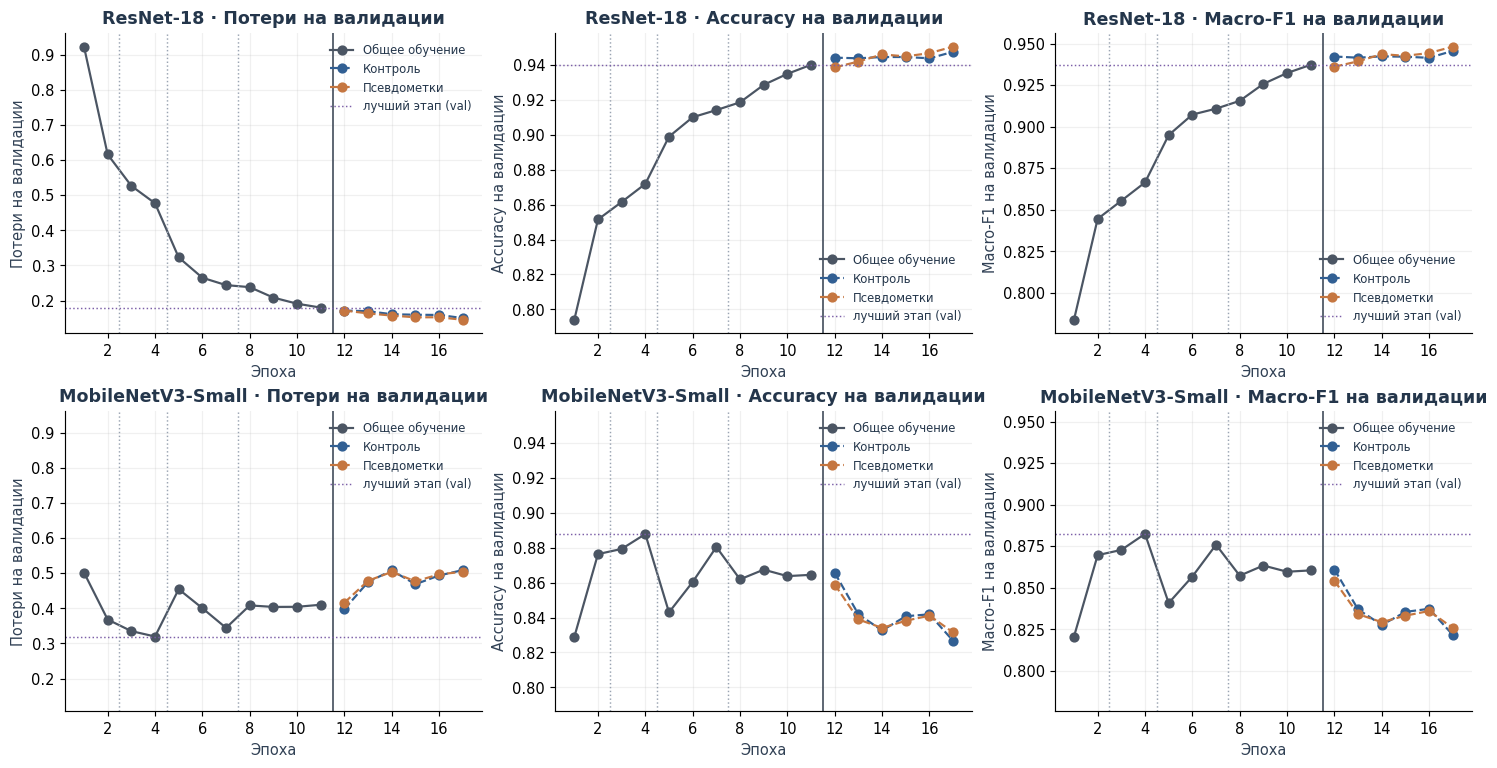

In [15]:
def plot_training_curves(
    history: pd.DataFrame,
) -> None:
    """Plot validation metrics for all architectures and branches."""
    metrics = (
        ("val_loss", "Потери на валидации"),
        ("val_accuracy", "Accuracy на валидации"),
        ("val_macro_f1", "Macro-F1 на валидации"),
    )
    boundaries = np.cumsum([phase.epochs for phase in PHASES])[:-1]
    fig, axes = plt.subplots(
        2,
        3,
        figsize=(14.0, 7.2),
        layout="constrained",
        sharey="col",
    )

    for row, architecture in enumerate(ARCHITECTURES):
        model_history = history[history["architecture"].eq(architecture)]
        common = model_history[model_history["experiment"].eq(COMMON_EXPERIMENT)]
        best = best_checkpoints[architecture]

        for column, (metric, label) in enumerate(metrics):
            ax = axes[row, column]
            ax.plot(
                common["plot_epoch"],
                common[metric],
                "o-",
                color=BRANCH_COLORS[COMMON_EXPERIMENT],
                label=COMMON_EXPERIMENT,
            )
            for experiment in BRANCH_EXPERIMENTS:
                branch = model_history[model_history["experiment"].eq(experiment)]
                ax.plot(
                    branch["plot_epoch"],
                    branch[metric],
                    "o--",
                    color=BRANCH_COLORS[experiment],
                    label=experiment,
                )
            for boundary in boundaries:
                ax.axvline(
                    boundary + 0.5,
                    color="#9aa4b2",
                    lw=1,
                    ls=":",
                )
            ax.axvline(
                COMMON_EPOCHS + 0.5,
                color="#4b5563",
                lw=1.2,
                ls="-",
            )
            ax.axhline(
                getattr(best, metric),
                color="#7b5ea7",
                lw=1,
                ls=":",
                label="лучший этап (val)",
            )
            ax.set(
                title=f"{architecture} · {label}",
                xlabel="Эпоха",
                ylabel=label,
            )
            ax.grid(alpha=0.18)
            ax.set_axisbelow(True)
            ax.legend(fontsize=8, frameon=False)

    plt.show()


plot_training_curves(history)

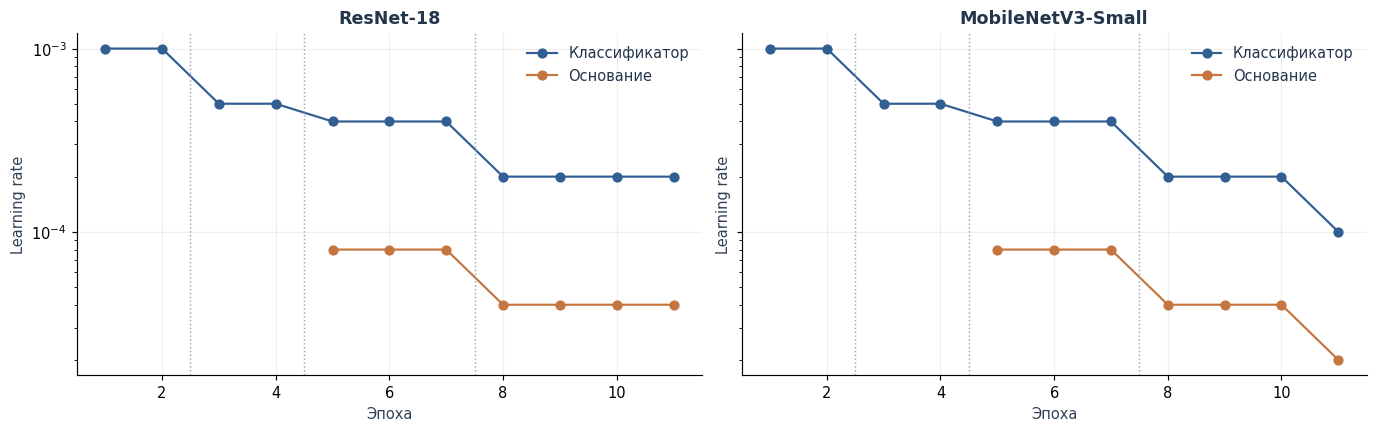

In [16]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13.0, 4.0),
    layout="constrained",
    sharey=True,
)
boundaries = np.cumsum([phase.epochs for phase in PHASES])[:-1]

for ax, architecture in zip(axes, ARCHITECTURES, strict=True):
    common = history[
        history["architecture"].eq(architecture)
        & history["experiment"].eq(COMMON_EXPERIMENT)
    ]
    ax.plot(
        common["plot_epoch"],
        common["lr_head"],
        "o-",
        color="#315f93",
        label="Классификатор",
    )
    ax.plot(
        common["plot_epoch"],
        common["lr_backbone"],
        "o-",
        color="#c57640",
        label="Основание",
    )
    for boundary in boundaries:
        ax.axvline(boundary + 0.5, color="#9aa4b2", lw=1, ls=":")
    ax.set(
        title=architecture,
        xlabel="Эпоха",
        ylabel="Learning rate",
        yscale="log",
    )
    ax.legend(frameon=False)
    ax.grid(alpha=0.18)
    ax.set_axisbelow(True)

plt.show()

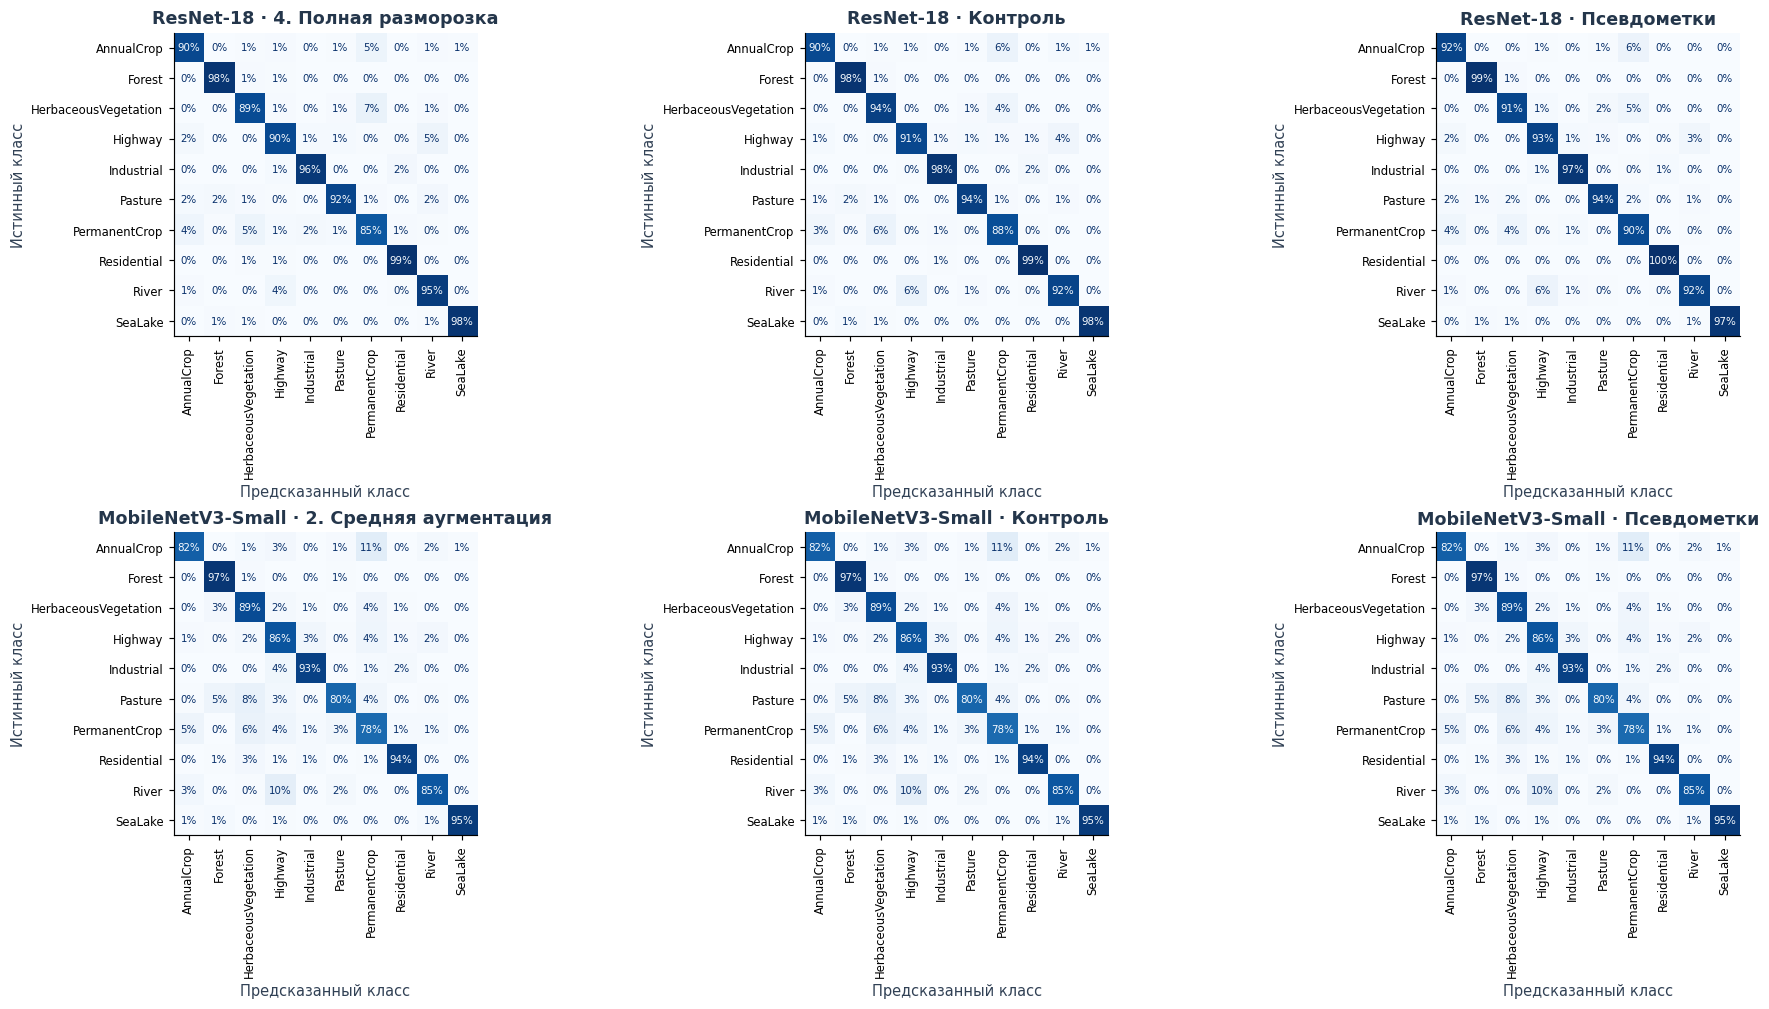

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(18.0, 9.5), layout="constrained")
for row, architecture in enumerate(ARCHITECTURES):
    best_name = best_checkpoints[architecture].name
    variants = [best_name, "Контроль", "Псевдометки"]
    for column, variant in enumerate(variants):
        ax = axes[row, column]
        ConfusionMatrixDisplay.from_predictions(
            targets[test_idx],
            test_predictions[(architecture, variant)],
            labels=class_ids,
            display_labels=class_names,
            normalize="true",
            values_format=".0%",
            cmap="Blues",
            colorbar=False,
            im_kw={"vmin": 0, "vmax": 1},
            text_kw={"fontsize": 7},
            xticks_rotation="vertical",
            ax=ax,
        )
        ax.set(
            title=f"{architecture} · {variant}",
            xlabel="Предсказанный класс",
            ylabel="Истинный класс",
        )
        ax.tick_params(axis="both", labelsize=8)

plt.show()

## 7. Выводы

**Итог.** Лучший результат показала **ResNet-18 с псевдометками**: **94,59% accuracy** и **94,42% macro-F1** на тесте. Контрольная ветка без псевдометок дала **94,37%** и **94,21%**, лучший этап до дообучения — **93,33%** и **93,15%**. У **MobileNetV3-Small** лучшим остался чекпойнт второго этапа: **88,37%** и **87,99%**; полная разморозка и обе ветки дообучения его не улучшили.

**Итеративная разморозка.** У ResNet-18 тестовая accuracy по этапам росла так: 85,04% → 87,11% → 91,93% → 93,33%, а `val_loss` снижался с 0,616 до 0,180. Разморозка `layer4` дала самый большой шаг (+4,8 п.п.), полная разморозка добавила ещё +1,4 п.п. У MobileNetV3-Small картина обратная: после второго этапа (88,37%) разморозка верхних блоков и всей сети ухудшила `val_loss` (0,320 → 0,344 → 0,404) и тест (86,85% → 84,37%). Поэтому для MobileNet выбран **второй этап**, а не последний. Это не ошибка выбора: при том же расписании lr полная разморозка маленькой сети переобучается; более мягкий backbone lr или другой график разморозки могли бы помочь.

**Псевдометки.** В каждом раунде отбиралось по 2 500 снимков (12,8% пула) при порогах 0,90 и 0,85; точность псевдометок — **99,9%** у ResNet-18 и **99,4–99,7%** у MobileNetV3-Small. Кандидатов было гораздо больше (12,6–17,6 тыс.), поэтому ограничение в 250 снимков на класс было активным. Прирост ResNet-18 относительно контроля составил **+0,22 п.п. accuracy** с 95%-м интервалом **[-0,33; +0,74]** и **+0,21 п.п. macro-F1** с интервалом **[-0,36; +0,77]** — на этом тесте статистически значимого прироста нет. У MobileNet обе ветки не смогли побить стартовый чекпойнт по `val_loss`, поэтому итоговое состояние осталось прежним (Δ = 0). Высокая точность псевдометок не гарантирует прироста: модель уже близка к своему пределу на 2 000 метках, а кап и порог ограничивают покрытие.

**Ошибки.** У ResNet-18 с псевдометками сильные классы — Residential (100% recall), Industrial и SeaLake (97%), Forest (99%); слабее всего AnnualCrop (82%): 6% уходит в HerbaceousVegetation и 6% — в Pasture. Река путается с шоссе в 6% случаев. У MobileNetV3-Small ошибок больше: AnnualCrop → Pasture 11%, River → Highway 10%, recall Pasture 80%, PermanentCrop 78%. Это согласуется с меньшей ёмкостью сети и объясняет разрыв в итоговой accuracy.

**Ожидаемый уровень.** На полной разметке EuroSAT публичные результаты ResNet-подобных сетей — около 98–99% accuracy. Здесь размечено только 7,4% датасета (2 000 из 27 000), поэтому 94–95% — ожидаемый и правдоподобный уровень, а не признак ошибки обучения.

**Ограничения.** Проверен один seed; точные числа могут отличаться на другом устройстве. Аугментация и разморозка меняются в одних и тех же фазах, поэтому их вклады нельзя разделить без отдельных контрольных прогонов. Кап псевдометок (250 на класс) и пороги 0,90/0,85 выбраны заранее и не настраивались; кандидатов значительно больше, так что увеличение покрытия — очевидный следующий шаг, но требует проверки на подтверждение ошибок. Для MobileNet стоит отдельно подобрать backbone lr и длительность разморозки. Более современные backbone (ConvNeXt, EfficientNet) и больше seed-ов — естественное продолжение.

**Практический вывод.** В этой постановке ResNet-18 заметно лучше MobileNetV3-Small. Основной вклад даёт итеративная разморозка с выбором чекпойнта по `val_loss` среди всех фаз; псевдолейблинг даёт небольшой и статистически неотличимый от нуля прирост при высокой точности отобранных меток. Ветку с псевдометками имеет смысл оставить как контролируемый эксперимент, а не как безусловное улучшение.